# Customer Churn Exploratory Data Analysis

This notebook explores the cleaned Telco customer churn data using descriptive statistics and visualizations only. It does not create predictive features, split data, or train models.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent
if PROJECT_ROOT.name != "Customer-Churn-Prediction":
    PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import DATA_PROCESSED_DIR, FIGURES_DIR

DATA_PATH = DATA_PROCESSED_DIR / "telco_churn_cleaned.csv"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
cleaned_shape = df.shape
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
)
sns.set_theme(style="whitegrid", context="notebook")
print(f"Loaded cleaned data with {cleaned_shape[0]:,} rows and {cleaned_shape[1]:,} columns from {DATA_PATH}")

Loaded cleaned data with 7,043 rows and 22 columns from data\processed\telco_churn_cleaned.csv


## 1. Dataset overview

This section checks the cleaned dataset's shape, column types, and descriptive statistics so later findings are grounded in the data actually being analyzed.

In [2]:
print("Cleaned file shape:", cleaned_shape)
print("\nData types:")
display(df.drop(columns=["tenure_group"]).dtypes.to_frame("dtype"))
print("\nNumeric summary:")
display(df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn_flag"]].describe().round(2))

Cleaned file shape: (7043, 22)

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Numeric summary:


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,churn_flag
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.16,0.27
std,24.56,30.09,2266.79,0.37,0.44
min,0.00,18.25,0.00,0.00,0.00
25%,9.00,35.50,398.55,0.00,0.00
50%,29.00,70.35,1394.55,0.00,0.00
75%,55.00,89.85,3786.60,0.00,1.00
max,72.00,118.75,8684.80,1.00,1.00


**Takeaway:** The cleaned dataset contains 7,043 customer records and 22 columns, including the analysis-only `churn_flag`. `TotalCharges` is numeric after cleaning, while `SeniorCitizen` remains a 0/1 field as documented in Phase 3 Part A.

## 2. Churn distribution

This section reports the target count and percentage so the class balance is explicit before comparing customer groups.

,Churn,count,percentage
0,No,5174,73.46
1,Yes,1869,26.54


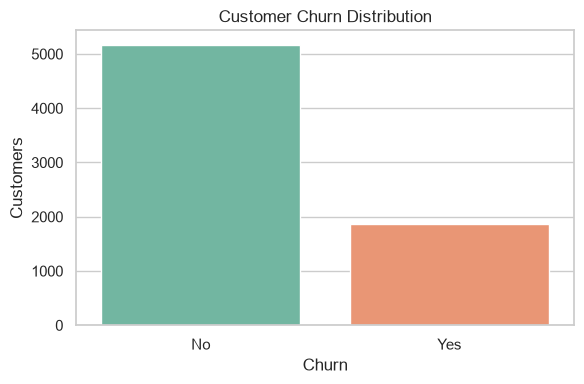

In [3]:
churn_summary = (
    df["Churn"].value_counts()
    .rename_axis("Churn")
    .reset_index(name="count")
)
churn_summary["percentage"] = churn_summary["count"] / len(df) * 100
display(churn_summary.round({"percentage": 2}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], hue="Churn", palette="Set2", legend=False, ax=ax)
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Customers")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "churn_distribution.png", dpi=150)
plt.show()

**Takeaway:** Churn is imbalanced: 1,869 customers (26.54%) churned and 5,174 (73.46%) did not. Comparisons should therefore use churn rates or percentages, not raw group counts alone.

## 3. Churn rates by customer groups

For each category, this section calculates the percentage of customers marked `Yes` for churn. This makes groups with different sizes comparable.


Contract


,count,churn_rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83



InternetService


,count,churn_rate
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40



PaymentMethod


,count,churn_rate
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


... (20 outputs left out)


StreamingTV


,count,churn_rate
StreamingTV,,
No,2810,33.52
Yes,2707,30.07
No internet service,1526,7.40



StreamingMovies


,count,churn_rate
StreamingMovies,,
No,2785,33.68
Yes,2732,29.94
No internet service,1526,7.40


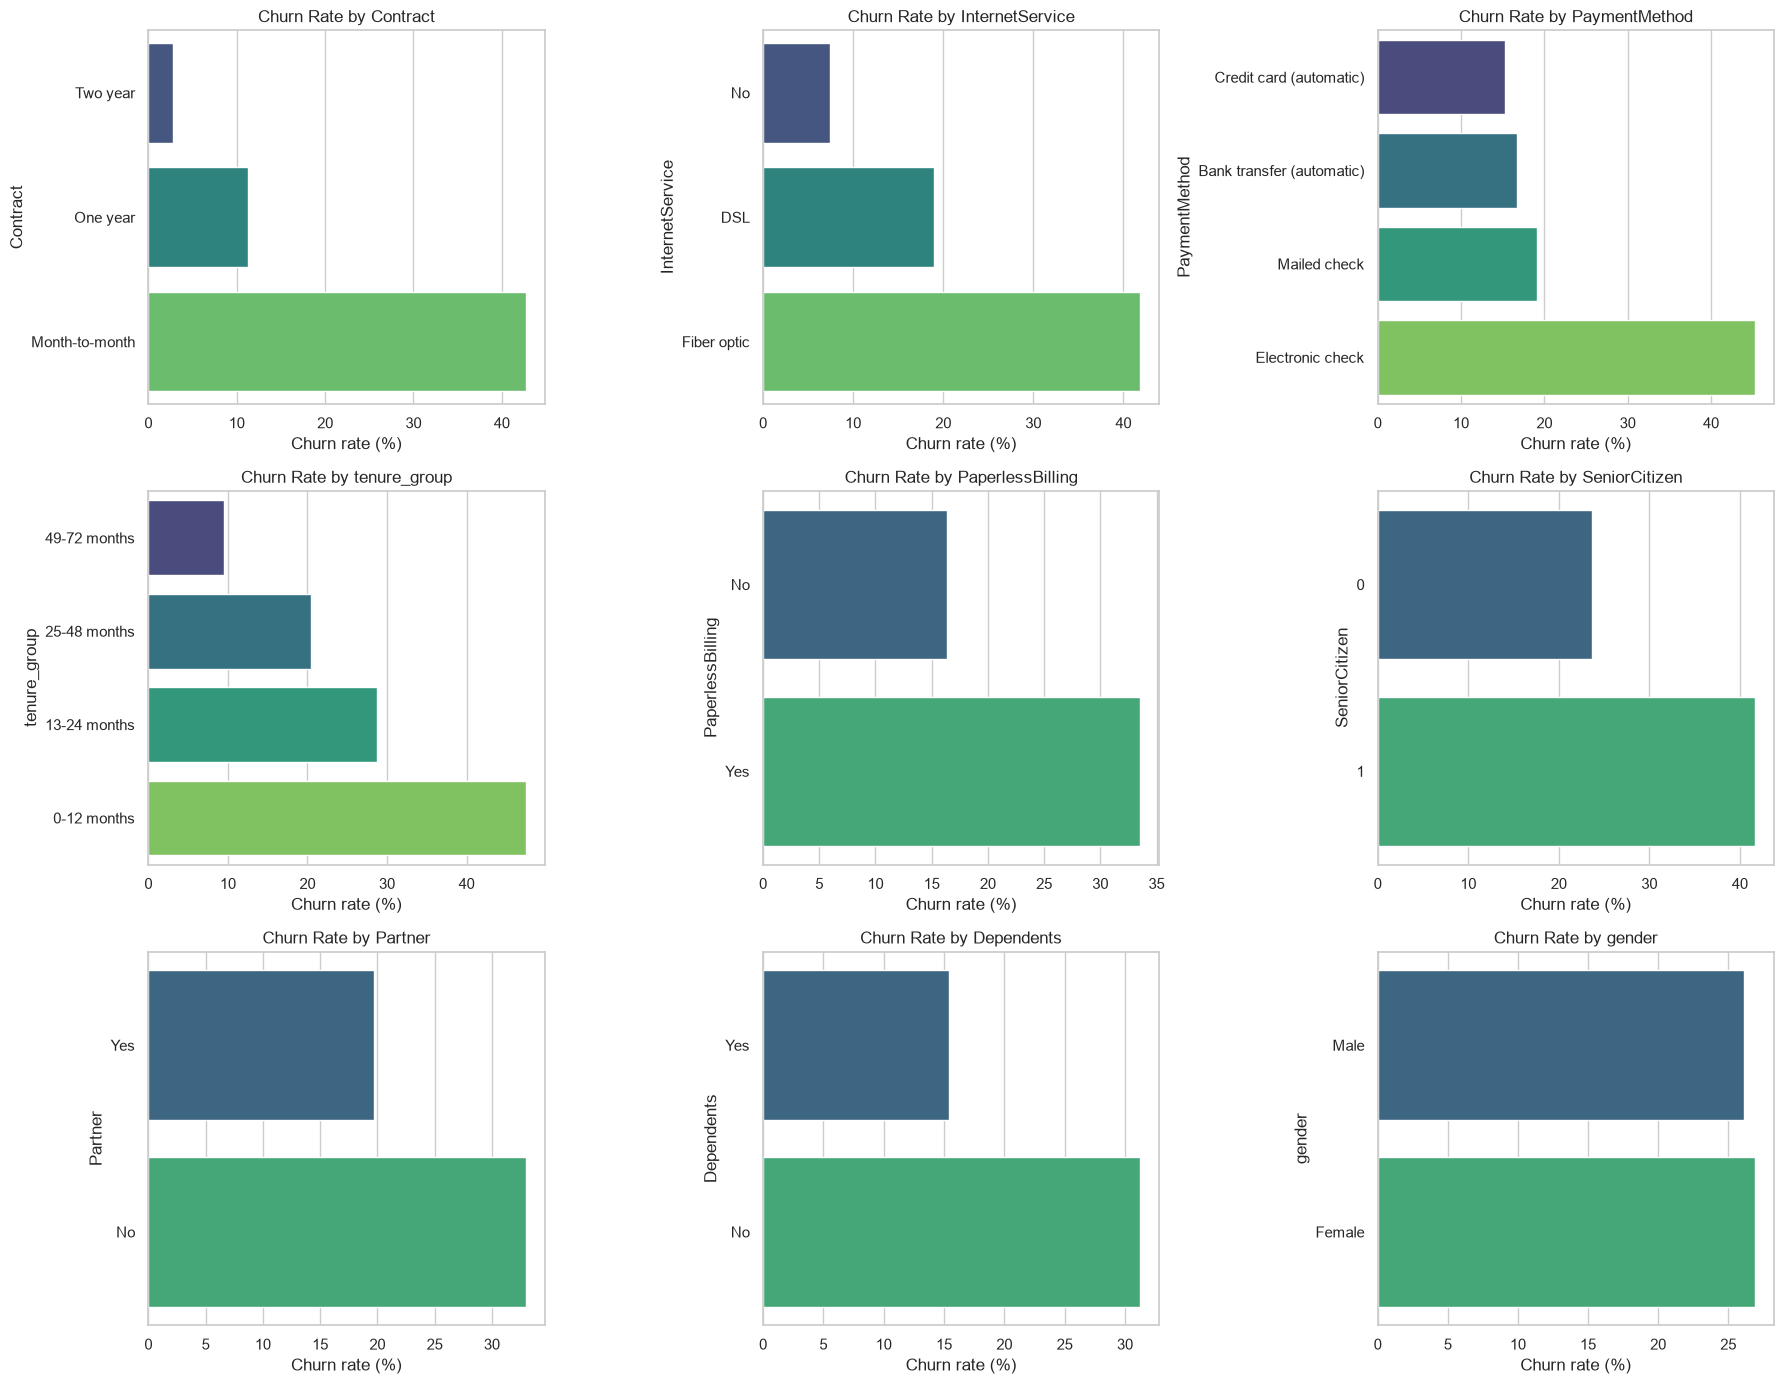

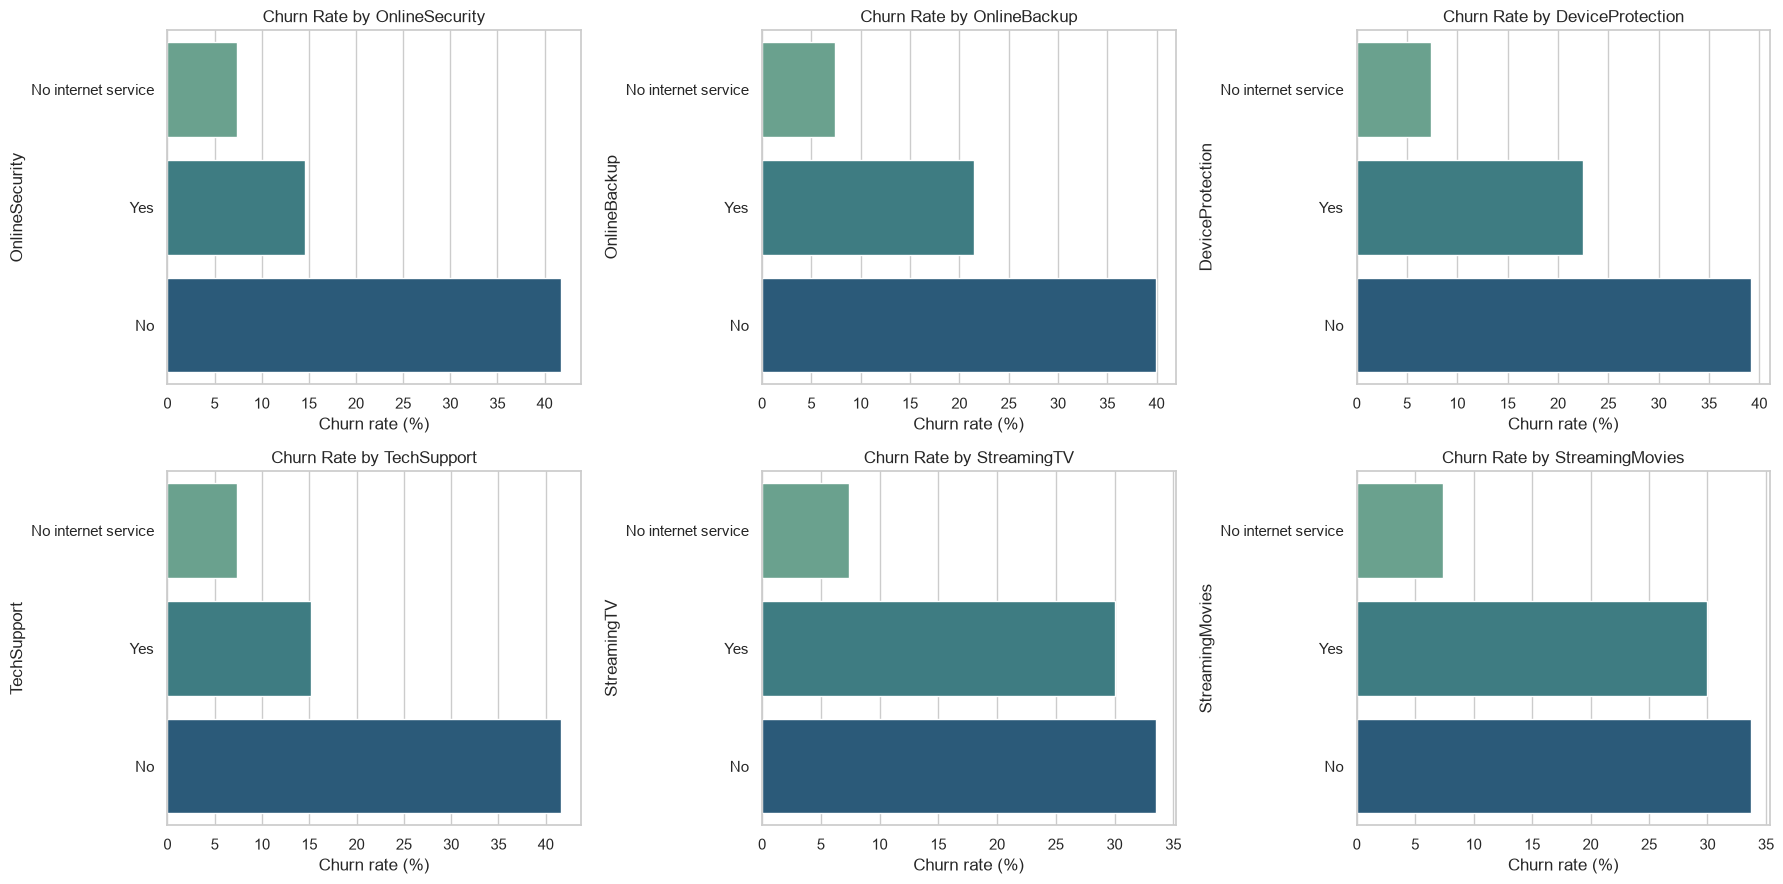

In [4]:
main_group_columns = [
    "Contract", "InternetService", "PaymentMethod", "tenure_group",
    "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "gender",
]
addon_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

def churn_rate_table(column):
    """Return group size and churn rate for one categorical column."""
    table = df.groupby(column, observed=False)["churn_flag"].agg(["count", "mean"])
    table = table.rename(columns={"mean": "churn_rate"})
    table["churn_rate"] = table["churn_rate"] * 100
    return table.sort_values("churn_rate", ascending=False).round(2)

for column in main_group_columns + addon_columns:
    print(f"\n{column}")
    display(churn_rate_table(column))

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, column in zip(axes.flat, main_group_columns):
    rates = churn_rate_table(column).sort_values("churn_rate")
    sns.barplot(x=rates["churn_rate"], y=rates.index.astype(str), hue=rates.index.astype(str), legend=False, palette="viridis", ax=ax)
    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "churn_rates_main_groups.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, column in zip(axes.flat, addon_columns):
    rates = churn_rate_table(column).sort_values("churn_rate")
    sns.barplot(x=rates["churn_rate"], y=rates.index.astype(str), hue=rates.index.astype(str), legend=False, palette="crest", ax=ax)
    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "churn_rates_addon_services.png", dpi=150)
plt.show()

**Takeaway:** The largest observed differences are associated with contract and tenure groups: month-to-month customers churned at 42.71% versus 2.83% for two-year customers, while 0-12 month tenure customers churned at 47.44% versus 9.51% for 49-72 months. Electronic check users had a 45.29% churn rate, and the gender difference was small (26.92% Female versus 26.16% Male). Add-on groups marked `No` generally had higher churn rates, while `No internet service` groups were 7.40%; these categories should remain distinct during Phase 4 encoding.

## 4. Numeric distributions by churn

These plots compare tenure, MonthlyCharges, and TotalCharges across the two observed churn classes. The charts show distributions rather than claiming causation.

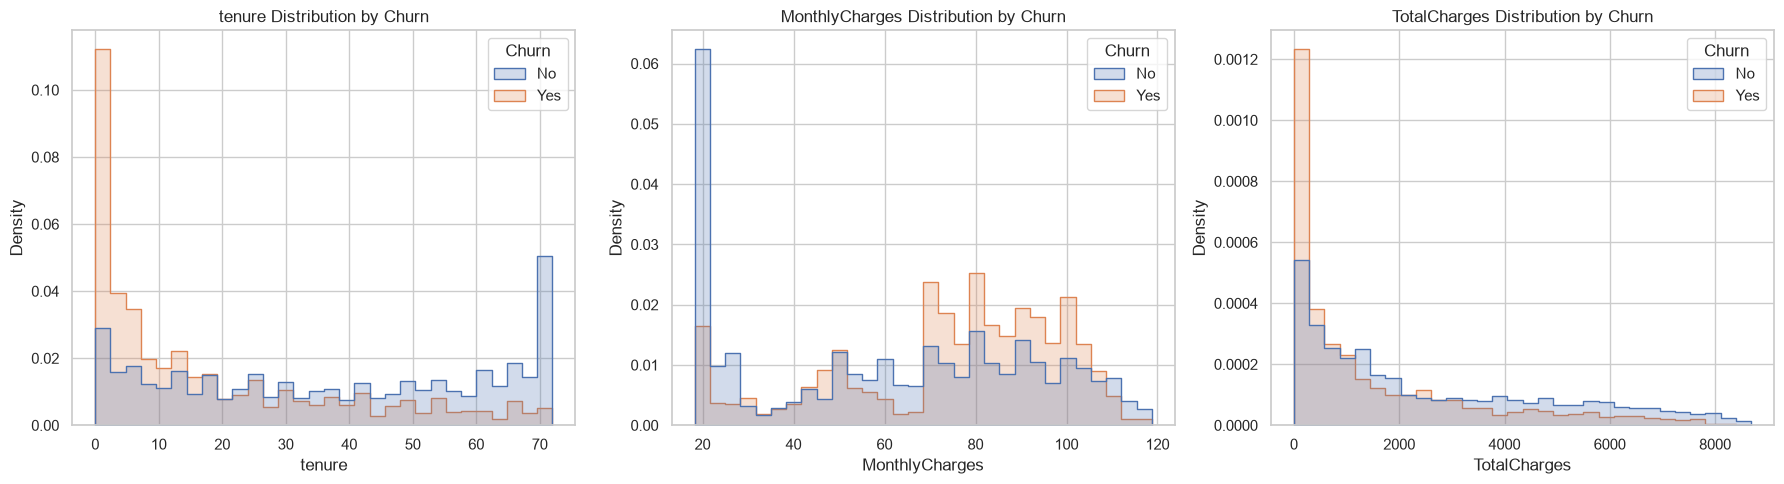

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


In [5]:
numeric_distribution_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, numeric_distribution_columns):
    sns.histplot(data=df, x=column, hue="Churn", bins=30, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{column} Distribution by Churn")
    ax.set_xlabel(column)
    ax.set_ylabel("Density")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_distributions_by_churn.png", dpi=150)
plt.show()

distribution_summary = df.groupby("Churn")[numeric_distribution_columns].mean().round(2)
display(distribution_summary)

**Takeaway:** The class means show lower tenure among churned customers (17.98 months) than non-churned customers (37.57 months), while mean MonthlyCharges are higher for churned customers ($74.44 versus $61.27). Mean TotalCharges are lower for churned customers ($1,531.80 versus $2,549.91), consistent with their shorter observed tenure.

## 5. Numeric correlation

This heatmap summarizes pairwise linear correlations among numeric columns, including the analysis target `churn_flag`. Correlation is descriptive and is not a causal or model result.

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,churn_flag
tenure,1.000,0.248,0.826,0.017,-0.352
MonthlyCharges,0.248,1.000,0.651,0.220,0.193
TotalCharges,0.826,0.651,1.000,0.103,-0.198
SeniorCitizen,0.017,0.220,0.103,1.000,0.151
churn_flag,-0.352,0.193,-0.198,0.151,1.000


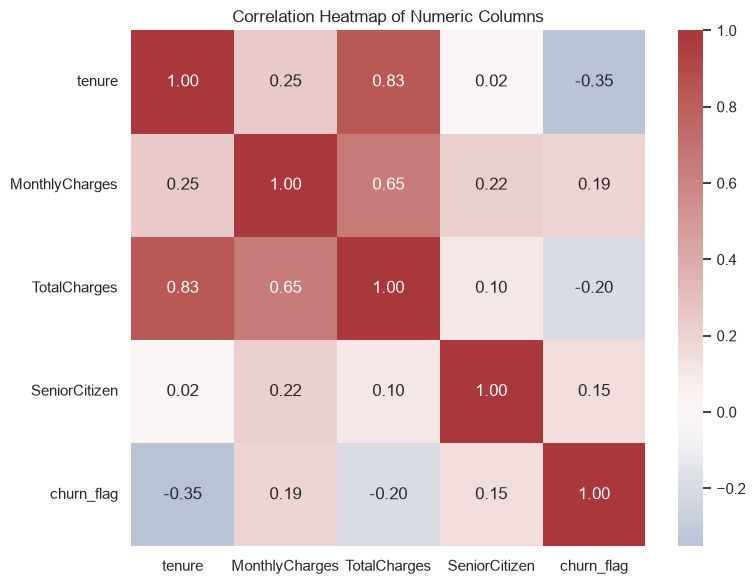

In [6]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn_flag"]
correlation = df[numeric_columns].corr()
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Columns")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "numeric_correlation_heatmap.png", dpi=150)
plt.show()

**Takeaway:** The strongest numeric association with `churn_flag` is negative for tenure (approximately -0.35), while MonthlyCharges has a positive association (approximately 0.19). These values describe this dataset and should not be interpreted as causal effects.

## 6. Ranked descriptive associations

This section ranks categorical factors by the spread between their highest and lowest observed churn rates. It is a compact descriptive summary, not feature selection or model importance.

In [7]:
association_rows = []
for column in main_group_columns + addon_columns:
    rates = df.groupby(column, observed=False)["churn_flag"].mean().mul(100)
    highest = rates.idxmax()
    lowest = rates.idxmin()
    association_rows.append({
        "factor": column,
        "highest_churn_group": str(highest),
        "highest_rate": round(float(rates.max()), 2),
        "lowest_churn_group": str(lowest),
        "lowest_rate": round(float(rates.min()), 2),
        "spread": round(float(rates.max() - rates.min()), 2),
    })
ranked_associations = pd.DataFrame(association_rows).sort_values("spread", ascending=False)
display(ranked_associations)

import plotly.express as px

contract_rates = churn_rate_table("Contract").reset_index()
interactive_contract = px.bar(
    contract_rates,
    x="Contract",
    y="churn_rate",
    color="Contract",
    title="Interactive Churn Rate by Contract",
    labels={"churn_rate": "Churn rate (%)"},
)
interactive_contract.write_html(FIGURES_DIR / "interactive_contract_churn.html", include_plotlyjs="cdn")
interactive_contract.show()

,factor,highest_churn_group,highest_rate,lowest_churn_group,lowest_rate,spread
0,Contract,Month-to-month,42.71,Two year,2.83,39.88
3,tenure_group,0-12 months,47.44,49-72 months,9.51,37.93
1,InternetService,Fiber optic,41.89,No,7.40,34.49
9,OnlineSecurity,No,41.77,No internet service,7.40,34.36
12,TechSupport,No,41.64,No internet service,7.40,34.23
10,OnlineBackup,No,39.93,No internet service,7.40,32.52
11,DeviceProtection,No,39.13,No internet service,7.40,31.72
2,PaymentMethod,Electronic check,45.29,Credit card (automatic),15.24,30.04
14,StreamingMovies,No,33.68,No internet service,7.40,26.28
13,StreamingTV,No,33.52,No internet service,7.40,26.12


**Takeaway:** Ranked by within-factor churn-rate spread, the largest differences are Contract (39.88 percentage points), tenure group (37.93 points), InternetService (34.49 points), OnlineSecurity (34.36 points), and TechSupport (34.23 points). The largest individual rates are 47.44% for 0-12 months tenure and 45.29% for Electronic check payment; these are descriptive associations, not model importance.